# 00 — EDA và tiền xử lý dữ liệu SecuraAI
Kiểm tra Windows-APT 2025 trước khi huấn luyện và giải thích lựa chọn feature.

In [2]:
from pathlib import Path
import json, hashlib
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import platform, sklearn
import importlib
from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
    accuracy_score, precision_score, recall_score, f1_score, fbeta_score, roc_auc_score,
    average_precision_score, confusion_matrix, make_scorer)
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.dummy import DummyClassifier
from securaai_ml.data import load_training_data
import securaai_ml.modeling as modeling_module
importlib.reload(modeling_module)  # tránh module cache cũ khi source vừa được cập nhật
from securaai_ml.modeling import (candidate_factories, decision_scores, parameter_grids,
    teaching_candidate_factories, teaching_parameter_grids)
from securaai_ml.schema import MODEL_FEATURES, TARGET_COLUMN, GROUP_COLUMN
from securaai_ml.train import temporal_train_validation_test

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
data, audit = load_training_data(ROOT / 'data' / 'raw')
train, validation, test = temporal_train_validation_test(data)
X_train, y_train = train.loc[:, MODEL_FEATURES], train[TARGET_COLUMN]
X_validation, y_validation = validation.loc[:, MODEL_FEATURES], validation[TARGET_COLUMN]
groups = train[GROUP_COLUMN]
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
audit

DatasetAudit(rows=102011, malicious=63792, benign=38219, groups=40, invalid_timestamps=0)

## 1. Kích thước và phân bố nhãn

,rows
target,
MALICIOUS_APT,63792
BENIGN,38219


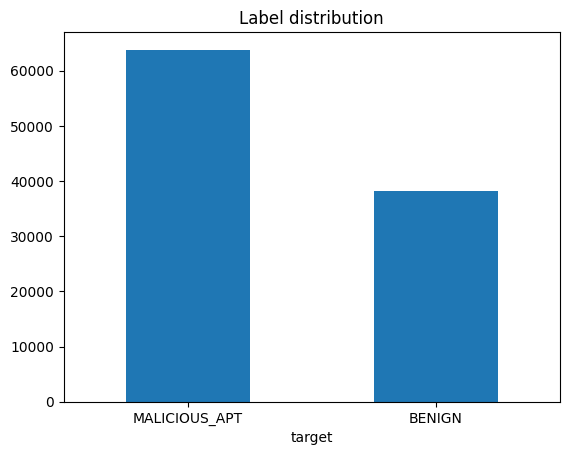

In [3]:
labels = data[TARGET_COLUMN].map({0:'BENIGN',1:'MALICIOUS_APT'})
display(labels.value_counts().to_frame('rows'))
labels.value_counts().plot.bar(rot=0, title='Label distribution'); plt.show()

## 2. Phân bố theo thời gian

target,0,1
collection_date,,
2024-10-28,30,173
2024-10-29,428,48
2024-10-30,3,0
2024-10-31,7,4
2024-11-01,13,10
2024-11-02,4,3
2024-11-05,161,684
2024-11-06,300,1929
2024-11-07,598,1385


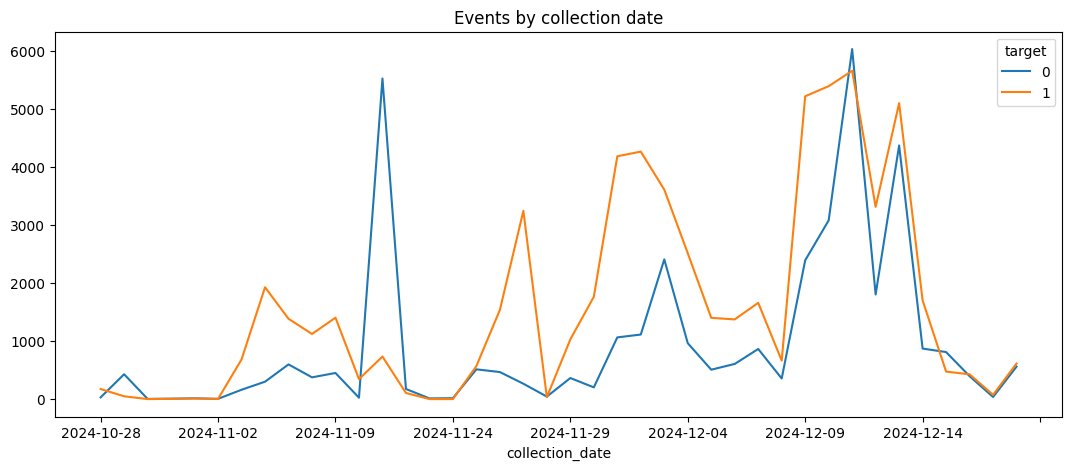

In [4]:
daily = data.groupby([GROUP_COLUMN,TARGET_COLUMN]).size().unstack(fill_value=0)
display(daily)
daily.plot(figsize=(13,5), title='Events by collection date'); plt.show()

## 3. Chia 60/20/20 theo thời gian
Giữ nguyên nhóm ngày để giảm leakage giữa các phiên thu thập liên quan.

In [5]:
splits=pd.DataFrame({'rows':[len(train),len(validation),len(test)]},index=['Train','Validation','Test']); splits['ratio']=splits.rows/len(data); splits

,rows,ratio
Train,61277,0.600690
Validation,20176,0.197783
Test,20558,0.201527


## 4. Feature engineering
Dùng event/provider/channel/severity, basename tiến trình, protocol/status, giờ/ngày, after-hours, cờ IP private/present, port và cờ tồn tại command/hash. Không dùng dữ liệu tiết lộ trực tiếp nhãn.

In [6]:
display(pd.Series(MODEL_FEATURES, name='model_feature').to_frame())
print('Missing values after canonical feature building:', int(data.loc[:, MODEL_FEATURES].isna().sum().sum()))

,model_feature
0,event_id
1,provider
2,channel
3,severity_value
4,decoder
5,location
6,input_type
7,logon_type
8,auth_package
9,integrity_level


Missing values after canonical feature building: 0


## 5. Giảm chiều
Không dùng PCA: dữ liệu phần lớn categorical sparse và feature đã chọn theo ngữ nghĩa bảo mật. OneHotEncoder dùng `min_frequency=2` để hạn chế category hiếm.

## Cập nhật pipeline dữ liệu hợp nhất

Notebook này thuộc bộ thí nghiệm SecuraAI mới. Có hai tầng kết quả cần phân biệt:

- **Thí nghiệm giảng dạy 00–10:** so sánh thuật toán trên cùng split Windows-APT để bảo đảm công bằng.
- **Baseline hợp nhất theo từng event:** Windows-APT 2025 + RADAR + log Wazuh đã bộc lộ domain shift khi test trực tiếp.
- **Ứng viên temporal hiện tại:** dùng dữ liệu sự kiện đã chuẩn hóa cùng thống kê hành vi ở các cửa sổ 1, 5, 15 và 60 phút.
- **Luồng triển khai AI:** ML sàng lọc nhanh; chỉ trường hợp vượt ngưỡng Validation mới chuyển sang Foundation-Sec để phân tích ngữ cảnh.
- **Quyết định cuối:** `BENIGN` không tạo alert, `SUSPICIOUS` chờ điều tra, `MALICIOUS` mới tạo hoặc gộp alert. Luồng AI đang bật không sử dụng baseline 7 ngày hay luật cũ để tự quyết định alert.

RADAR bổ sung ground truth ransomware/Sysmon theo từng mẫu thực thi. Log Wazuh hiện tại chỉ là kiểm thử lab và weak-benign; không được trình bày như bằng chứng production. Test, threshold và dữ liệu ngoài miền được giữ tách biệt để giảm leakage.

In [7]:
import pandas as pd

combined_artifact_dir = ROOT / 'artifacts-combined-candidate'
combined_metadata_path = combined_artifact_dir / 'model_metadata.json'
combined_source_report_path = ROOT / 'reports' / 'combined_candidate_by_source.json'
temporal_artifact_dir = ROOT / 'artifacts-temporal-candidate'
temporal_metadata_path = temporal_artifact_dir / 'model_metadata.json'

if combined_metadata_path.exists():
    combined_metadata = json.loads(combined_metadata_path.read_text(encoding='utf-8'))
    display(pd.DataFrame({
        'value': [
            combined_metadata['selectedModel'],
            combined_metadata['lockedThreshold'],
            ', '.join(combined_metadata['datasets']),
            combined_metadata['test']['f2'],
            combined_metadata['test']['precision'],
            combined_metadata['test']['recall'],
        ]
    }, index=['selected_model','locked_threshold','datasets','combined_test_f2','combined_test_precision','combined_test_recall']))
else:
    print('Chưa có artifacts-combined-candidate. Chạy scripts/train_combined_candidate.py trước.')

if temporal_metadata_path.exists():
    temporal_metadata = json.loads(temporal_metadata_path.read_text(encoding='utf-8'))
    display(pd.DataFrame({
        'value': [
            temporal_metadata['selectedModel'], temporal_metadata['lockedThreshold'],
            temporal_metadata['validation']['f2'], temporal_metadata['test']['f2'],
            temporal_metadata['test']['falsePositiveRate'], temporal_metadata['status'],
        ]
    }, index=['temporal_model','temporal_threshold','validation_f2','test_f2','test_fpr','status']))
else:
    print('Chưa có artifacts-temporal-candidate. Chạy scripts/train_temporal_candidate.py trước.')


,value
selected_model,logistic_regression
locked_threshold,0.442104
datasets,"Windows-APT 2025 v4, RADAR v0.0.1-beta"
combined_test_f2,0.994966
combined_test_precision,0.990039
combined_test_recall,0.996205


,value
temporal_model,bagging
temporal_threshold,0.5
validation_f2,1.0
test_f2,1.0
test_fpr,0.0
status,EXPERIMENTAL_CONTROLLED_LAB_ONLY


## Nguồn dữ liệu mới và vai trò của từng nguồn

| Nguồn | Vai trò | Nhãn | Cách chia |
|---|---|---|---|
| Windows-APT 2025 v4 | hành vi Windows APT mô phỏng | MITRE/Wazuh-derived | theo ngày 60/20/20 |
| RADAR v0.0.1-beta | Sysmon ransomware và goodware | ground truth theo executable/sample | mẫu độc lập 60/20/20 |
| SecuraAI/Wazuh lab | kiểm tra khả năng nhận log của project | kịch bản kiểm soát | chỉ train bổ sung hoặc external test |
| Wazuh benign candidates | giảm cảnh báo giả trên log gần miền đích | weak label, phải rà soát | chỉ bổ sung Train |

Không trộn Test trở lại Train. Không coi weak label hoặc bốn log lab là ground truth production.

In [8]:
if combined_source_report_path.exists():
    source_report = json.loads(combined_source_report_path.read_text(encoding='utf-8'))
    source_rows = []
    for source, values in source_report.items():
        row = {'source': source}
        if isinstance(values, dict):
            for key in ['rows','accuracy','precision','recall','f2','roc_auc','predicted_benign','predicted_malicious']:
                if key in values: row[key] = values[key]
        source_rows.append(row)
    display(pd.DataFrame(source_rows).set_index('source'))


,accuracy,precision,recall,f2,roc_auc,rows,predicted_benign,predicted_malicious
source,,,,,,,,
windows_apt_test,0.977722,0.968123,0.993594,0.988393,0.997274,NaN,NaN,NaN
radar_test,0.999195,1.000000,0.997359,0.997886,1.000000,NaN,NaN,NaN
wazuh_benign_candidate,NaN,NaN,NaN,NaN,NaN,85.0,85.0,0.0


## Dataset scenario temporal

Bộ scenario hiện có **3.000 session / khoảng 24.600 event**, chia nguyên session thành Train/Validation/Test và có manifest ground truth riêng. Ngoài burst benign sát ngưỡng, dữ liệu còn có password spraying, distributed attack, success-after-failure và hard-negative nhiều tài khoản/IP độc lập. Nhãn event phản ánh thời điểm ra quyết định: event thứ năm trong burst xác thực/VPN và event thứ mười trong burst ứng dụng mới bắt đầu là malicious. Metric rất cao trên bộ này đo khả năng tái hiện kịch bản mô phỏng, không phải accuracy production.

In [9]:
scenario_path=ROOT/'data'/'securaai_scenarios'/'securaai_scenarios.csv'
if scenario_path.exists():
    scenario_data=pd.read_csv(scenario_path,dtype=str).fillna('')
    display(pd.crosstab(scenario_data['session_split'],scenario_data['reviewer_label'],margins=True))
    display(scenario_data.groupby(['session_split','scenario'])['scenario_id'].nunique().rename('sessions').to_frame())
    assert scenario_data.groupby('scenario_id')['session_split'].nunique().max()==1
    print('Không có session nào đi qua nhiều split.')


reviewer_label,BENIGN,MALICIOUS_APT,All
session_split,,,
TEST,4124,866,4990
TRAIN,12445,2554,14999
VALIDATION,3951,902,4853
All,20520,4322,24842


sessions
session_split scenario                          
TEST          APP_DENIAL_BURST                13
              APP_DISTRIBUTED_DENIAL          12
              APP_NORMAL_ACCESS               73
              APP_SUBTHRESHOLD_DENIAL         71
              APP_SUCCESS_AFTER_DENIAL        16
...                                          ...
VALIDATION    VPN_DISTRIBUTED_ATTACK          11
              VPN_FAILURE_BURST               16
              VPN_NORMAL                      83
              VPN_PASSWORD_SPRAY               9
              VPN_SUBTHRESHOLD_BURST          78

[66 rows x 1 columns]

Không có session nào đi qua nhiều split.
